# Hyderabad Metro Expansion: Where Should the Next Lines Go?

**Question:** which parts of Hyderabad have the most people left without metro access, and where should the next 3 metro lines go to reach the most of them per kilometre?

**Data:** OpenStreetMap (metro stations and tracks, bus stops, schools, colleges, roads) and WorldPop (population), on a 1 km grid over the built-up city.

**Method:**
1. Keep only metro stations that are actually **operational** (Red, Blue and Green lines).
2. Score every 1 km square: *demand* (people, schools, colleges) x *gap* (distance to metro 60%, job hubs 30%, bus only 10%, since the metro is the main commuting mode this project plans for).
3. Group the top 15% of squares into hotspots.
4. Build candidate lines that may only **start at a line end (an extension) or at a junction (an interchange station)**, and that **follow wide roads** (trunk, primary, secondary), preferring the widest, through a hotspot.
5. Rank lines by people served per km of road, counting only people more than 1.5 km from a station, and never counting the same people twice.
6. Place stations every ~1.25 km along each corridor and count the people within an 800 m walk of them.

Part 1 (above) builds the grid and the data. Part 2 (below) cleans the station list, scores every square and finds the corridors.

**Before you run:** download the WorldPop India 2020 1 km population-counts file (`ind_ppp_2020_1km_Aggregated.tif`, the plain *Aggregated* file, not the `UNadj` one) from worldpop.org and put it in the same folder as this notebook. Everything else is downloaded from OpenStreetMap while the notebook runs.


In [1]:
%pip install osmnx geopandas folium mapclassify rasterstats rasterio


Note: you may need to restart the kernel to use updated packages.


In [2]:
import osmnx as ox
import geopandas as gpd
import numpy as np
from shapely.geometry import box

# Keyless basemap (OpenStreetMap's own tiles block saved HTML files: "API required")
ESRI = "https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}"
ATTR = "Esri"

# Rectangle around Hyderabad + Secunderabad (lon/lat), roughly the ORR area
west, south, east, north = 78.28, 17.28, 78.63, 17.58
city = gpd.GeoDataFrame(geometry=[box(west, south, east, north)], crs=4326).to_crs(32644)

# Cut it into 1 km squares
minx, miny, maxx, maxy = city.total_bounds
cells = [box(x, y, x + 1000, y + 1000)
         for x in np.arange(minx, maxx, 1000)
         for y in np.arange(miny, maxy, 1000)]
grid = gpd.GeoDataFrame(geometry=cells, crs=city.crs)

print(len(grid))
grid.to_crs(4326).explore()

1292


In [3]:
poly = city.to_crs(4326).union_all()   # city outline in lat/lon

def get_points(tags):
    data = ox.features_from_polygon(poly, tags)
    data = data.to_crs(32644)
    data["geometry"] = data.geometry.centroid   # turn everything into points
    return data[["geometry"]].reset_index(drop=True)

metro   = get_points({"station": "subway"})
bus     = get_points({"highway": "bus_stop"})
schools = get_points({"amenity": ["school", "college"]})

print("metro:", len(metro), "bus:", len(bus), "schools:", len(schools))

metro: 71 bus: 600 schools: 864


In [4]:
# centre point of each square
centres = grid.copy()
centres["geometry"] = grid.centroid

def nearest_dist(points):
    j = gpd.sjoin_nearest(centres, points, distance_col="d")
    return j.groupby(j.index)["d"].min()

grid["metro_dist"] = nearest_dist(metro)
grid["bus_dist"]   = nearest_dist(bus)

# count schools inside each square
joined = gpd.sjoin(schools, grid, predicate="within")
counts = joined.groupby("index_right").size()
grid["schools"] = counts.reindex(grid.index).fillna(0)

print(grid[["metro_dist", "bus_dist", "schools"]].describe())

         metro_dist     bus_dist      schools
count   1292.000000  1292.000000  1292.000000
mean    6645.435861  1733.691214     0.668731
std     4517.756925  1518.404773     1.493652
min       54.794620    33.530007     0.000000
25%     2759.457216   655.612028     0.000000
50%     6152.345691  1274.895061     0.000000
75%     9568.747981  2284.362816     1.000000
max    20462.399095  8671.970514    17.000000


In [5]:
from shapely.geometry import Point

hubs = gpd.GeoSeries(
    [Point(78.3772, 17.4435),   # Hitec City
     Point(78.3489, 17.4401),   # Gachibowli
     Point(78.3426, 17.4172),   # Financial District
     Point(78.4983, 17.4399)],  # Secunderabad
    crs=4326).to_crs(32644)

grid["hub_dist"] = centres.geometry.apply(lambda p: hubs.distance(p).min())

In [6]:
bus = get_points({"highway": "bus_stop", "public_transport": "platform"})

In [7]:
grid["schools"] = [schools.within(sq.buffer(1000)).sum() for sq in grid.geometry]

In [8]:
from rasterstats import zonal_stats
import glob, os

# WorldPop India 2020, 1 km population counts. Put the .tif in the same folder as this notebook.
RASTER = "ind_ppp_2020_1km_Aggregated.tif"
if not os.path.exists(RASTER):
    found = glob.glob("*.tif")
    assert found, f"No .tif file in {os.getcwd()}. Download the WorldPop file (see the note at the top) and put it here."
    RASTER = found[0]
print("Using:", RASTER)

stats = zonal_stats(grid.to_crs(4326), RASTER, stats="sum")
grid["population"] = [s["sum"] or 0 for s in stats]

print(grid["population"].describe())
print("Total people:", grid["population"].sum())


Using: ind_ppp_2020_1km_Aggregated.tif
count     1292.000000
mean      6864.786188
std       6387.201425
min          0.000000
25%       1449.128265
50%       5180.783936
75%      10853.774170
max      56449.160156
Name: population, dtype: float64
Total people: 8869303.755183166


In [9]:
grid = grid[grid["population"] > 100].reset_index(drop=True)
print(len(grid))

1259


## Score only the real city

The grid is cut down to the **built-up city** (dense squares connected to Charminar), so empty land at the edge of the rectangle is not scored.


In [10]:
# 1. Recompute bus distance on the CURRENT grid, using the bus stops
#    that include the extra "platform" tag (that fix was never applied to bus_dist)
pts = grid.copy()
pts["geometry"] = grid.centroid

j = gpd.sjoin_nearest(pts, bus, distance_col="d")
grid["bus_dist"] = j.groupby(j.index)["d"].min()

print(len(bus), "bus stops")
print(grid["bus_dist"].describe())


727 bus stops
count    1259.000000
mean     1601.584901
std      1459.817699
min        25.880449
25%       581.251832
50%      1127.255578
75%      2105.000956
max      8671.970514
Name: bus_dist, dtype: float64


In [11]:
# 2. Find the built-up city: dense squares that connect to Charminar
from collections import deque
from shapely.geometry import Point

DENSE = 5000   # people per 1 km square that counts as "city" (try 3000 or 8000)

# position of every square on the 1 km lattice
cx, cy = grid.centroid.x, grid.centroid.y
col = ((cx - cx.min()) / 1000).round().astype(int)
row = ((cy - cy.min()) / 1000).round().astype(int)
pos = list(zip(row, col))

dense = {p for p, pop in zip(pos, grid["population"]) if pop >= DENSE}

# start at the square nearest Charminar
charminar = gpd.GeoSeries([Point(78.4747, 17.3616)], crs=4326).to_crs(grid.crs).iloc[0]
start = pos[int(grid.centroid.distance(charminar).values.argmin())]
dense.add(start)

# spread outwards through touching dense squares
city_sq = {start}
queue = deque([start])
while queue:
    r, c = queue.popleft()
    for dr in (-1, 0, 1):
        for dc in (-1, 0, 1):
            n = (r + dr, c + dc)
            if n in dense and n not in city_sq:
                city_sq.add(n)
                queue.append(n)

# fill small holes (lakes, parks): add a square if 5+ of its 8 neighbours are city
filled = set()
for r, c in set(pos) - city_sq:
    k = sum((r + dr, c + dc) in city_sq
            for dr in (-1, 0, 1) for dc in (-1, 0, 1) if (dr, dc) != (0, 0))
    if k >= 5:
        filled.add((r, c))
city_sq |= filled

grid_city = grid[[p in city_sq for p in pos]].copy().reset_index(drop=True)
print(len(grid), "->", len(grid_city), "squares")
print("People inside:", round(grid_city["population"].sum() / 1e6, 2), "million")

grid_city.to_crs(4326).explore(column="population", cmap="YlOrRd", legend=True)


1259 -> 693 squares
People inside: 7.78 million


---
## Part 2: Candidate metro corridors

Run these cells in order, after the cells above. They need `grid_city`, `poly`, `gpd` and `ox` to be in memory. The road download takes a minute or two.

**Note:** the first cell below keeps only operational stations (OpenStreetMap also lists planned ones) and computes `metro_dist` from them.


In [12]:
# Helper functions (nothing is plotted here)
import numpy as np
import pandas as pd
from collections import deque
from shapely.geometry import Point, LineString


def find_hotspots(xy, score, top=0.15, min_squares=3):
    """Group the top `top` share of squares (by score) into clusters of touching squares."""
    cut = np.quantile(score, 1 - top)
    hot = np.where(score >= cut)[0]
    col = np.round((xy[:, 0] - xy[:, 0].min()) / 1000).astype(int)
    row = np.round((xy[:, 1] - xy[:, 1].min()) / 1000).astype(int)
    where = {(row[i], col[i]): i for i in hot}
    seen, clusters = set(), []
    for start in where:
        if where[start] in seen:
            continue
        members, queue = [], deque([start])
        seen.add(where[start])
        while queue:
            r, c = queue.popleft()
            members.append(where[(r, c)])
            for dr in (-1, 0, 1):
                for dc in (-1, 0, 1):
                    n = (r + dr, c + dc)
                    if n in where and where[n] not in seen:
                        seen.add(where[n])
                        queue.append(n)
        if len(members) >= min_squares:
            clusters.append(np.array(members))
    return clusters

def dist_to_segment(P, a, b):
    ab = b - a
    t = np.clip(((P - a) @ ab) / (ab @ ab), 0, 1)
    proj = a + t[:, None] * ab
    return np.hypot(*(P - proj).T)

def dist_to_path(P, path):
    d = np.full(len(P), np.inf)
    for a, b in zip(path[:-1], path[1:]):
        if (a == b).all():
            continue
        d = np.minimum(d, dist_to_segment(P, a, b))
    return d

def pick_corridors(xy, pop, far, clusters, anchors_xy, anchor_names, route_fn,
                   n=8, min_km=2, max_km=15, max_detour=1.8, buffer_m=1000,
                   sector_of=None, diag=None):
    """Candidate lines may only START at an anchor (a line end or a junction) and
    follow the route that route_fn(start, end) returns (a dict with path, length).
    If sector_of is given, each new corridor goes to a part of the city with no corridor yet (while any is left).
    If diag is a list, it is filled with the reason every candidate was kept or dropped."""
    def note(k, name, status, **kw):
        if diag is not None:
            diag.append({"cluster": k, "anchor": name, "status": status, **kw})

    cand = []
    for k, idx in enumerate(clusters):
        w = pop[idx]
        centre = (xy[idx] * w[:, None]).sum(axis=0) / w.sum()
        for a, name in zip(anchors_xy, anchor_names):
            if np.hypot(*(centre - a)) < min_km * 1000:
                note(k, name, "hotspot too close to this start point")
                continue
            u = (centre - a) / np.hypot(*(centre - a))
            b = a + u * ((xy[idx] - a) @ u).max()          # aim for the far side of the hotspot
            r = route_fn(a, b)
            if r is None:
                note(k, name, "no wide road close enough")
                continue
            length_km = r["length"] / 1000
            if length_km > max_km:
                note(k, name, "route too long")
                continue
            if r["length"] > max_detour * np.hypot(*(b - a)):
                note(k, name, "road too winding")
                continue
            mask = (dist_to_path(xy, r["path"]) <= buffer_m) & far
            solo = pop[mask].sum() / length_km
            note(k, name, "ok", solo_per_km=solo, length_km=length_km)
            cand.append(dict(route=r, anchor=name, cluster=k, mask=mask, length_km=length_km, solo=solo,
                             hotspot_squares=len(idx), sector=sector_of(b) if sector_of else None))

    chosen, covered, used = [], np.zeros(len(xy), bool), set()

    def pick(pool):
        best, best_val, best_new = None, 0, 0
        for c in pool:
            if c["cluster"] in used:
                continue
            new = pop[c["mask"] & ~covered].sum()
            val = new / c["length_km"]
            if val > best_val:
                best, best_val, best_new = c, val, new
        if best is not None:
            np.logical_or(covered, best["mask"], out=covered)
            used.add(best["cluster"])
            chosen.append({**best, "people_served": best_new, "people_per_km": best_val})
        return best

    while len(chosen) < n:
        # best line overall first; after that, prefer a part of the city with no line yet
        seen = {c["sector"] for c in chosen}
        fresh = [c for c in cand if c["sector"] not in seen] if sector_of else []
        if pick(fresh) is None and pick(cand) is None:
            break
    chosen.sort(key=lambda c: -c["people_per_km"])
    return chosen

def place_stations(path, spacing=1250):
    """Evenly spaced stations along a road path; the last one sits at the end of the line."""
    path = path[np.r_[True, (np.diff(path, axis=0) != 0).any(axis=1)]]   # drop repeated points
    seg = np.hypot(*np.diff(path, axis=0).T)
    cum = np.r_[0, np.cumsum(seg)]
    n = max(1, int(round(cum[-1] / spacing)))
    marks = np.linspace(0, cum[-1], n + 1)[1:]
    return np.c_[np.interp(marks, cum, path[:, 0]), np.interp(marks, cum, path[:, 1])]


def make_score(wm=0.6, wb=0.1, wh=0.3):
    """Need score = demand x gap, with the metro/bus/hub weights you choose."""
    s = grid_city.copy()
    for c in ["metro_dist", "bus_dist", "hub_dist"]:
        s[c] = s[c].clip(upper=s[c].quantile(0.90))
    s["colleges"] = s["colleges"].clip(upper=max(s["colleges"].quantile(0.95), 1))   # stop one campus dominating
    for c in ["population", "metro_dist", "bus_dist", "hub_dist", "schools", "colleges"]:
        s[c + "_s"] = (s[c] - s[c].min()) / (s[c].max() - s[c].min())
    demand = (s["population_s"] * 2 + s["schools_s"] + s["colleges_s"]) / 4
    gap = wm * s["metro_dist_s"] + wb * s["bus_dist_s"] + wh * s["hub_dist_s"]
    return demand * gap


In [13]:
# 1. Keep only OPERATIONAL metro stations
#    (the Green Line runs JBS Parade Ground to MG Bus Station; the Old City extension is not built yet)
raw = ox.features_from_polygon(poly, {"station": "subway"})
pts = raw.to_crs(32644).geometry.centroid

st_all = pd.DataFrame({"name": raw["name"].fillna("") if "name" in raw.columns else "",
                       "x": pts.x.values, "y": pts.y.values}, index=raw.index)
st_all = st_all.reset_index(drop=True)
raw = raw.reset_index(drop=True)
st_all["norm"] = st_all["name"].str.lower().str.replace(r"[^a-z0-9]", "", regex=True)

# a) drop anything tagged proposed / under construction
flag_cols = [c for c in raw.columns
             if any(w in c.lower() for w in ("proposed", "construction", "planned", "disused", "abandoned"))]
planned = raw[flag_cols].notna().any(axis=1) if flag_cols else pd.Series(False, index=raw.index)
if "railway" in raw.columns:
    planned = planned | raw["railway"].isin(["proposed", "construction"])

# b) drop the Old City (Phase 2) stations that are not built yet
NOT_BUILT = ["salarjung", "charminar", "shalibanda", "shamshergunj", "shamsher",
             "jangammet", "falaknuma", "chandrayangutta"]
not_built = st_all["norm"].apply(lambda n: any(k in n for k in NOT_BUILT))

drop = planned.values | not_built.values
st = st_all[~drop].copy()

# c) one row per station (OSM often maps the same station several times)
st["key"] = st["norm"].where(st["norm"] != "", "unnamed" + st.index.astype(str))
st = st.groupby("key", as_index=False).agg(name=("name", "first"), norm=("norm", "first"),
                                           x=("x", "mean"), y=("y", "mean"))

ll = gpd.GeoSeries(gpd.points_from_xy(st["x"], st["y"]), crs=32644).to_crs(4326)
st["lat"], st["lon"] = ll.y.values, ll.x.values

print(len(st_all), "OSM subway features ->", len(st), "operational stations")
print("Dropped as planned / not built:", sorted(set(st_all.loc[drop, "name"]) - {""}))
print("\nSouthernmost stations kept (the Green Line should stop at MG Bus Station):")
print(st.sort_values("lat").head(6)[["name", "lat", "lon"]].round(4).to_string(index=False))

# 2. Recompute metro distance for every square against the cleaned station list
stations_xy = st[["x", "y"]].values
xy = np.c_[grid_city.centroid.x, grid_city.centroid.y]
grid_city["metro_dist"] = np.hypot(xy[:, None, 0] - stations_xy[None, :, 0],
                                   xy[:, None, 1] - stations_xy[None, :, 1]).min(axis=1)
print("\nmedian distance to metro:", round(grid_city["metro_dist"].median()), "m")


71 OSM subway features -> 64 operational stations
Dropped as planned / not built: ['Charminar (u/c)', 'Falaknuma Terminal (u/c)', 'Jungametta (u/c)', 'Salar Jung Museum (u/c)', 'Shah Ali Banda (u/c)', 'Shamserganj (u/c)']

Southernmost stations kept (the Green Line should stop at MG Bus Station):
                     name     lat     lon
L. B. Nagar Metro Station 17.3498 78.5479
        Victoria Memorial 17.3619 78.5439
            Chaitanyapuri 17.3683 78.5359
            Dilsukh Nagar 17.3686 78.5257
              Musarambagh 17.3711 78.5119
             Moosarambagh 17.3711 78.5120

median distance to metro: 3513 m


In [14]:
# 2. Colleges and universities: extra demand parameter (students travel a lot)
coll_raw = ox.features_from_polygon(poly, {"amenity": ["college", "university"]})
cp = coll_raw.to_crs(32644).geometry.centroid
college_xy = np.c_[cp.x, cp.y]

# one campus is often mapped as many buildings, so merge points within ~300 m
college_xy = np.unique(np.round(college_xy / 300), axis=0) * 300

d = np.hypot(xy[:, None, 0] - college_xy[None, :, 0], xy[:, None, 1] - college_xy[None, :, 1])
grid_city["colleges"] = (d <= 1000).sum(axis=1)       # colleges within 1 km of each square

print(len(college_xy), "college sites;", int((grid_city["colleges"] > 0).sum()), "squares have one within 1 km")
print(grid_city["colleges"].describe())


360 college sites; 287 squares have one within 1 km
count    693.000000
mean       1.382395
std        2.569740
min        0.000000
25%        0.000000
50%        0.000000
75%        2.000000
max       18.000000
Name: colleges, dtype: float64


In [15]:
# 3. Where a new line is allowed to START: line ends (extensions) and junctions (interchanges)
#    Approximate positions are matched to the real OSM station by name, then by location.
ANCHORS = {   # name: (approx lat, approx lon, what it is, name keywords)
    "Miyapur":           (17.4967, 78.3583, "Red Line end",                         ["miyapur"]),
    "LB Nagar":          (17.3463, 78.5521, "Red Line end",                         ["lbnagar"]),
    "Nagole":            (17.3893, 78.5598, "Blue Line end",                        ["nagole"]),
    "Raidurg":           (17.4340, 78.3810, "Blue Line end",                        ["raidurg"]),
    "JBS Parade Ground": (17.4466, 78.4983, "Green Line end + Blue/Green junction", ["jbs", "paradeground"]),
    "MG Bus Station":    (17.3787, 78.4833, "Green Line end + Red/Green junction",  ["mgbs", "mgbusstation", "mahatmagandhi"]),
    "Ameerpet":          (17.4375, 78.4483, "Red/Blue junction",                    ["ameerpet"]),
}

def to_xy(lat, lon):
    p = gpd.GeoSeries([Point(lon, lat)], crs=4326).to_crs(32644).iloc[0]
    return np.array([p.x, p.y])

anchor_names, anchor_xy = [], []
for name, (lat, lon, kind, keys) in ANCHORS.items():
    approx = to_xy(lat, lon)
    d = pd.Series(np.hypot(st["x"] - approx[0], st["y"] - approx[1]), index=st.index)
    named = st[st["norm"].apply(lambda n: any(k in n for k in keys)) & (d < 3000)]
    if len(named):
        row, how = st.loc[d[named.index].idxmin()], "by name"
    elif d.min() < 800:
        row, how = st.loc[d.idxmin()], "by location"
    else:
        row, how = None, "NOT FOUND - using the approximate position"
    pos = approx if row is None else np.array([row["x"], row["y"]])
    anchor_names.append(name)
    anchor_xy.append(pos)
    print(f"{name:18s} {kind:38s} -> {'' if row is None else row['name']:22s} ({how}, moved {np.hypot(*(pos - approx)):.0f} m)")

anchor_xy = np.array(anchor_xy)


Miyapur            Red Line end                           -> miyapur metro          (by name, moved 1536 m)
LB Nagar           Red Line end                           -> L. B. Nagar Metro Station (by name, moved 592 m)
Nagole             Blue Line end                          -> Nagole                 (by name, moved 193 m)
Raidurg            Blue Line end                          -> Raidurg                (by name, moved 993 m)
JBS Parade Ground  Green Line end + Blue/Green junction   -> Parade Grounds (Green Line) (by name, moved 247 m)
MG Bus Station     Green Line end + Red/Green junction    -> Mahatma Gandhi Bus Station (Green Line) (by name, moved 294 m)
Ameerpet           Red/Blue junction                      -> Ameerpet (Red Line)    (by name, moved 422 m)


In [16]:
# 4. Road network: wide roads only (trunk, primary, secondary)
import networkx as nx

WIDE_ROADS = '["highway"~"^(trunk|primary|secondary)$"]'
G = ox.graph_from_polygon(poly, custom_filter=WIDE_ROADS, simplify=True)
G = ox.projection.project_graph(G, to_crs=32644)

U = G.to_undirected()                                              # a metro can run either way along a road
U = U.subgraph(max(nx.connected_components(U), key=len)).copy()    # keep the main connected network

def first(v):
    return v[0] if isinstance(v, list) else v

CLASS_COST = {"trunk": 1.0, "primary": 1.0, "secondary": 1.4}      # lower = preferred (wider road)

def road_cost(d):
    f = CLASS_COST.get(first(d.get("highway")), 1.6)
    try:
        lanes = int(str(first(d.get("lanes", ""))).split(";")[0])
        f *= 0.85 if lanes >= 4 else (1.3 if lanes <= 1 else 1.0)  # use lane count when OSM has it
    except ValueError:
        pass
    return d["length"] * f

for u, v, k, d in U.edges(keys=True, data=True):
    d["cost"] = road_cost(d)

node_ids = list(U.nodes)
node_xy = np.array([[U.nodes[n]["x"], U.nodes[n]["y"]] for n in node_ids])

def road_route(a, b, max_snap=1500):
    """Cheapest route along wide roads between two points (None if no wide road is close enough)."""
    i, j = (np.hypot(*(node_xy - p).T).argmin() for p in (a, b))
    if np.hypot(*(node_xy[i] - a)) > max_snap or np.hypot(*(node_xy[j] - b)) > max_snap or i == j:
        return None
    try:
        nodes = nx.shortest_path(U, node_ids[i], node_ids[j], weight="cost")
    except nx.NetworkXNoPath:
        return None
    pts, length, main, names = [], 0.0, 0.0, []
    for u, v in zip(nodes[:-1], nodes[1:]):
        d = min(U[u][v].values(), key=lambda e: e["cost"])
        start = np.array([U.nodes[u]["x"], U.nodes[u]["y"]])
        end = np.array([U.nodes[v]["x"], U.nodes[v]["y"]])
        seg = np.array(d["geometry"].coords) if "geometry" in d else np.array([start, end])
        if np.hypot(*(seg[0] - start)) > np.hypot(*(seg[-1] - start)):
            seg = seg[::-1]
        pts.extend(seg.tolist() if not pts else seg[1:].tolist())
        length += d["length"]
        if first(d.get("highway")) in ("trunk", "primary"):
            main += d["length"]
        nm = d.get("name")
        for n in (nm if isinstance(nm, list) else [nm]):
            if isinstance(n, str) and n not in names:
                names.append(n)
    return {"path": np.array(pts), "length": length,
            "main_share": main / length if length else 0.0, "names": names}

print(len(U.nodes), "road junctions,", len(U.edges), "road segments")
for name, p in zip(anchor_names, anchor_xy):
    print(f"{name:18s} is {np.hypot(*(node_xy - p).T).min():.0f} m from the nearest wide road")


1734 road junctions, 2660 road segments
Miyapur            is 543 m from the nearest wide road
LB Nagar           is 142 m from the nearest wide road
Nagole             is 126 m from the nearest wide road
Raidurg            is 83 m from the nearest wide road
JBS Parade Ground  is 50 m from the nearest wide road
MG Bus Station     is 136 m from the nearest wide road
Ameerpet           is 131 m from the nearest wide road


In [17]:
# 5. Find the corridors
pop = grid_city["population"].values
far = (grid_city["metro_dist"] > 1500).values          # people NOT already near a station

score = make_score()
clusters = find_hotspots(xy, score.values)
N_CORRIDORS = 3     # how many new metro lines to propose
BALANCED = True      # True: the 3 lines go to 3 different areas (north, south, east, west), strongest first
MAX_ROUTE_KM = 15   # longest route allowed. The answer is sensitive to this: see the sensitivity cell in Part 3

centre = (xy * pop[:, None]).sum(axis=0) / pop.sum()      # middle of the city, weighted by people
def sector_of(p):
    ang = np.degrees(np.arctan2(p[1] - centre[1], p[0] - centre[0]))
    if -45 <= ang < 45:
        return "East"
    if 45 <= ang < 135:
        return "North"
    return "West" if (ang >= 135 or ang < -135) else "South"

diag = []
chosen = pick_corridors(xy, pop, far, clusters, anchor_xy, anchor_names, road_route,
                        n=N_CORRIDORS, sector_of=sector_of if BALANCED else None, diag=diag,
                        max_km=MAX_ROUTE_KM)
print(len(clusters), "hotspots ->", len(chosen), "corridors\n")
if not chosen:
    print("No corridor found. Try adding tertiary to WIDE_ROADS in the road cell.")

lines = gpd.GeoDataFrame(
    {"rank": range(1, len(chosen) + 1),
     "area": [sector_of(c["route"]["path"][-1]) for c in chosen],
     "starts_at": [c["anchor"] for c in chosen],
     "start_type": [ANCHORS[c["anchor"]][2] for c in chosen],
     "length_km": [round(c["length_km"], 1) for c in chosen],
     "main_road_share": [f"{c['route']['main_share']:.0%}" for c in chosen],
     "via": [", ".join(c["route"]["names"][:5]) for c in chosen],
     "people_served": [int(c["people_served"]) for c in chosen],
     "people_per_km": [int(c["people_per_km"]) for c in chosen]},
    geometry=[LineString(c["route"]["path"]) for c in chosen],
    crs=grid_city.crs)

ll = lines.to_crs(4326)
lines["end_lat_lon"] = [f"{g.coords[-1][1]:.3f}, {g.coords[-1][0]:.3f}" for g in ll.geometry]

print(lines.drop(columns="geometry").to_string(index=False))


12 hotspots -> 3 corridors

 rank  area         starts_at                           start_type  length_km main_road_share                                                                                                                                                                                                                    via  people_served  people_per_km    end_lat_lon
    1 South          LB Nagar                         Red Line end        5.9            100%                                                                                                                                              Vijaywada Highway, Inner Ring Road, Bairamalguda Road, IS Sadan Main Road         150761          25596 17.356, 78.505
    2 North JBS Parade Ground Green Line end + Blue/Green junction       10.3             97%                                                                                                                         Wellington Road, Hyderabad - Mancherial Highway, S

In [18]:
# 6. Place new stations along each corridor and count who they serve
SPACING = 1250     # metres between stations (a common rule of thumb for metro)
WALK = 800         # metres people will walk to a station

covered = np.zeros(len(xy), bool)      # so nobody is counted twice
rows, geoms = [], []
for rank, c in enumerate(chosen, start=1):
    for stop, p in enumerate(place_stations(c["route"]["path"], SPACING), start=1):
        near = (np.hypot(*(xy - p).T) <= WALK) & far & ~covered
        covered |= near
        rows.append({"corridor": rank, "stop": stop, "starts_at": c["anchor"],
                     "new_people_within_800m": int(pop[near].sum())})
        geoms.append(Point(*p))

new_stations = gpd.GeoDataFrame(rows, geometry=geoms, crs=grid_city.crs)
ll = new_stations.to_crs(4326)
new_stations["lat_lon"] = [f"{g.y:.4f}, {g.x:.4f}" for g in ll.geometry]

summary = new_stations.groupby("corridor").agg(stations=("stop", "count"),
                                              catchment=("new_people_within_800m", "sum"))
lines["stations"] = lines["rank"].map(summary["stations"])
lines["catchment_people"] = lines["rank"].map(summary["catchment"])
lines["people_per_station"] = (lines["catchment_people"] / lines["stations"]).round(-2).astype(int)

print(lines[["rank", "starts_at", "length_km", "stations", "catchment_people", "people_per_station"]]
      .to_string(index=False))
print()
print(new_stations.drop(columns="geometry").to_string(index=False))


 rank         starts_at  length_km  stations  catchment_people  people_per_station
    1          LB Nagar        5.9         5             83330               16700
    2 JBS Parade Ground       10.3         8            191874               24000
    3           Miyapur       10.3         8            165766               20700

 corridor  stop         starts_at  new_people_within_800m          lat_lon
        1     1          LB Nagar                       0 17.3430, 78.5448
        1     2          LB Nagar                   14400 17.3441, 78.5338
        1     3          LB Nagar                   14159 17.3457, 78.5229
        1     4          LB Nagar                   27853 17.3498, 78.5127
        1     5          LB Nagar                   26918 17.3565, 78.5054
        2     1 JBS Parade Ground                       0 17.4542, 78.4981
        2     2 JBS Parade Ground                   26671 17.4643, 78.5031
        2     3 JBS Parade Ground                   22601 17.4732, 

In [19]:
# 7. Map: need score + every metric + existing stations + start points + proposed corridors
import folium

# one copy of the grid with every metric, rounded so the hover text is readable
g = grid_city.assign(need_score=score).copy()
for c in ["need_score"]:
    g[c] = g[c].round(3)
for c in ["population", "metro_dist", "bus_dist", "hub_dist"]:
    g[c] = g[c].round(0)
g = g.to_crs(4326)

METRICS = ["population", "metro_dist", "bus_dist", "hub_dist", "schools", "colleges"]
LABELS  = {"population": "Population", "metro_dist": "Distance to metro (m)",
           "bus_dist": "Distance to bus stop (m)", "hub_dist": "Distance to job hub (m)",
           "schools": "Schools within 1 km", "colleges": "Colleges within 1 km"}

# ---- base layer: need score, hover shows every metric ----
m = g.explore(
    column="need_score", cmap="YlOrRd", legend=True, name="Need score", tiles=ESRI, attr=ATTR,
    tooltip=["need_score"] + METRICS)

# ---- one switchable layer per metric (hidden until you tick it) ----
for c in METRICS:
    g.explore(m=m, column=c, cmap="YlOrRd", legend=False, show=False,
              tooltip=[c], name=LABELS[c],
              style_kwds={"fillOpacity": 0.7, "weight": 0.3})

# ---- existing stations ----
stations_gdf = gpd.GeoDataFrame(st[["name"]], geometry=gpd.points_from_xy(st["x"], st["y"]), crs=32644)
stations_gdf.to_crs(4326).explore(m=m, color="blue", marker_kwds={"radius": 4},
                                  tooltip=["name"], name="Operational metro stations")

# ---- allowed start points ----
anchors_gdf = gpd.GeoDataFrame(
    {"name": anchor_names, "type": [ANCHORS[n][2] for n in anchor_names]},
    geometry=[Point(*p) for p in anchor_xy], crs=32644)
anchors_gdf.to_crs(4326).explore(m=m, color="purple", marker_kwds={"radius": 8},
                                 tooltip=["name", "type"], name="Allowed start points")

# ---- job hubs (same order as the `hubs` series in the notebook) ----
HUB_NAMES = ["Hitec City", "Gachibowli", "Financial District", "Secunderabad"]
hubs_gdf = gpd.GeoDataFrame({"name": HUB_NAMES}, geometry=list(hubs.geometry), crs=hubs.crs)
hubs_gdf.to_crs(4326).explore(m=m, color="orange", marker_kwds={"radius": 8},
                              tooltip=["name"], name="Job hubs")

# ---- wide roads ----
roads = ox.graph_to_gdfs(G, nodes=False).reset_index()
roads["pair"] = [tuple(sorted(t)) for t in zip(roads["u"], roads["v"])]
roads = roads.drop_duplicates(["pair", "key"])                 # each two-way road once
roads["highway"] = roads["highway"].astype(str)
roads[["highway", "geometry"]].to_crs(4326).explore(m=m, color="grey", style_kwds={"weight": 1},
                                                    tooltip=["highway"], name="Wide roads")

# ---- proposed corridors and new stations ----
lines.to_crs(4326).explore(m=m, color="black", style_kwds={"weight": 6},
                           tooltip=["rank", "area", "starts_at", "via", "length_km", "main_road_share",
                                    "stations", "catchment_people", "people_per_station"],
                           name="Proposed corridors")

new_stations.to_crs(4326).explore(m=m, color="red", marker_kwds={"radius": 5},
                                  tooltip=["corridor", "stop", "new_people_within_800m", "lat_lon"],
                                  name="New stations")

# ---- colleges (merged campus points) ----
colleges_gdf = gpd.GeoDataFrame(geometry=[Point(*p) for p in college_xy], crs=32644)
colleges_gdf.to_crs(4326).explore(m=m, color="green", marker_kwds={"radius": 3},
                                  tooltip=False, name="Colleges")

folium.LayerControl().add_to(m)
m.save("hyderabad_metro_corridors.html")   # shareable file, opens in any browser
m

In [20]:
# 8. Robustness: do the hotspots change if the weights change?
base = set(np.where(score.values >= np.quantile(score.values, 0.85))[0])

for w in [(0.5, 0.1, 0.4), (0.7, 0.1, 0.2), (0.6, 0.2, 0.2)]:
    t = make_score(*w).values
    other = set(np.where(t >= np.quantile(t, 0.85))[0])
    print(f"metro/bus/hub = {w[0]:.2f}/{w[1]:.2f}/{w[2]:.2f}: "
          f"{len(base & other) / len(base):.0%} of hotspot squares stay the same")


metro/bus/hub = 0.50/0.10/0.40: 92% of hotspot squares stay the same
metro/bus/hub = 0.70/0.10/0.20: 94% of hotspot squares stay the same
metro/bus/hub = 0.60/0.20/0.20: 92% of hotspot squares stay the same


In [21]:
# Map: existing metro in its own line colours, extensions in a darker shade, new routes in purple
import folium

# ---- colours: (existing line, darker shade used for its extensions) ----
LINE_COLOURS = {"Red":   ("#e53935", "#7f0000"),    # bright red   -> dark maroon
                "Blue":  ("#1e88e5", "#0a1f7a"),    # bright blue  -> dark navy
                "Green": ("#43a047", "#0b4d1c")}    # bright green -> dark forest green

# Start points that are the END of a line -> a line from there is an extension of that line
EXT_OF = {"Miyapur": "Red", "LB Nagar": "Red", "Nagole": "Blue", "Raidurg": "Blue",
          "JBS Parade Ground": "Green", "MG Bus Station": "Green"}

# Rough centre-lines (lat, lon) of the 3 lines. Only used to tell which line a track piece belongs to.
SKELETON = {"Red":   [(17.4967, 78.3583), (17.4936, 78.3911), (17.4849, 78.4138),
                      (17.4375, 78.4483), (17.3787, 78.4833), (17.3463, 78.5521)],
            "Blue":  [(17.3893, 78.5598), (17.4466, 78.4983), (17.4375, 78.4483), (17.4340, 78.3810)],
            "Green": [(17.4466, 78.4983), (17.3787, 78.4833)]}
skel = gpd.GeoSeries({k: LineString([(lon, lat) for lat, lon in v]) for k, v in SKELETON.items()},
                     crs=4326).to_crs(32644)

def nearest_line(geom):
    return min(skel.index, key=lambda k: skel[k].distance(geom))

# ---- 1. Existing tracks from OpenStreetMap (no planned / under-construction pieces) ----
tracks = ox.features_from_polygon(poly, {"railway": "subway"}).reset_index(drop=True)
bad = [c for c in tracks.columns
       if any(w in c.lower() for w in ("proposed", "construction", "planned", "disused", "abandoned"))]
if bad:
    tracks = tracks[~tracks[bad].notna().any(axis=1)]
tracks = tracks[tracks.geom_type.isin(["LineString", "MultiLineString"])][["geometry"]]
tracks = tracks.to_crs(32644).explode(index_parts=False).reset_index(drop=True)
tracks["line"] = [nearest_line(g.interpolate(0.5, normalized=True)) for g in tracks.geometry]
print(len(tracks), "existing track pieces:", tracks["line"].value_counts().to_dict())

# existing stations get the colour of the nearest line
stn = gpd.GeoDataFrame(st[["name"]], geometry=gpd.points_from_xy(st["x"], st["y"]), crs=32644)
stn["line"] = [nearest_line(g) for g in stn.geometry]

# ---- 2. Colour the proposed lines ----
lines["kind"]   = [f"{EXT_OF[a]} Line extension" if a in EXT_OF else "New route" for a in lines["starts_at"]]
lines["colour"] = [LINE_COLOURS[EXT_OF[a]][1] if a in EXT_OF else PURPLE for a in lines["starts_at"]]

# ---- 3. Build the map (bottom to top) ----
m2 = folium.Map(location=[17.40, 78.48], zoom_start=11, tiles=ESRI, attr=ATTR)

# need-score squares underneath (switch on/off with the layer control)
grid_city.assign(need_score=score).to_crs(4326).explore(
    m=m2, column="need_score", cmap="YlOrRd", legend=False,
    tooltip=["need_score", "population", "colleges"], name="Need score")

for ln, (bright, _) in LINE_COLOURS.items():
    sub = tracks[tracks["line"] == ln]
    if len(sub):
        sub.to_crs(4326).explore(m=m2, color=bright, style_kwds={"weight": 5, "opacity": 1},
                                 tooltip=False, name=f"{ln} Line (existing)")
    s = stn[stn["line"] == ln]
    if len(s):
        s.to_crs(4326).explore(m=m2, color=bright, marker_kwds={"radius": 4},
                               tooltip=["name"], name=f"{ln} Line stations")

for i, row in lines.iterrows():
    one = lines.loc[[i]].to_crs(4326)
    one.explore(m=m2, color=row["colour"], style_kwds={"weight": 8, "opacity": 1},
                tooltip=["rank", "kind", "area", "starts_at", "via", "length_km",
                         "stations", "catchment_people"],
                name=f"New line {row['rank']}: {row['kind']}")
    ns = new_stations[new_stations["corridor"] == row["rank"]].to_crs(4326)
    if len(ns):
        ns.explore(m=m2, color=row["colour"], marker_kwds={"radius": 7},
                   tooltip=["corridor", "stop", "new_people_within_800m"],
                   name=f"New stations {row['rank']}")

# ---- 4. View, legend, layer switch, save ----
minx, miny, maxx, maxy = grid_city.to_crs(4326).total_bounds
m2.fit_bounds([[miny, minx], [maxy, maxx]])

items = [(f"{ln} Line (existing)", bright) for ln, (bright, _) in LINE_COLOURS.items()]
items += [(f"{ln} Line extension (new)", dark) for ln, (_, dark) in LINE_COLOURS.items()]
legend = "".join(f'<span style="color:{c};font-size:16px;font-weight:bold;">&#9473;&#9473;</span> {t}<br>'
                 for t, c in items)
m2.get_root().html.add_child(folium.Element(
    '<div style="position:fixed;bottom:25px;left:25px;z-index:9999;background:white;'
    f'padding:8px 12px;border:1px solid #999;border-radius:6px;font-size:13px;">{legend}</div>'))

folium.LayerControl().add_to(m2)
m2.save("hyderabad_old_vs_new_metro.html")
m2


242 existing track pieces: {'Blue': 131, 'Red': 103, 'Green': 8}


---
## Part 3: Why these 3 lines?

The three winning hotspots are not the highest-scoring ones. This table lists every hotspot with its need score, colleges, best route and result, so you can see why each one won or lost. Run it after the corridor cells above.

In [22]:
# Why these 3? Compare every hotspot, not just the winners
won = {c["cluster"]: rank for rank, c in enumerate(chosen, start=1)}

# each hotspot's best route if there were no 3-line cap and no "one line per area" rule
alone = pick_corridors(xy, pop, far, clusters, anchor_xy, anchor_names, road_route,
                       n=len(clusters), sector_of=None, max_km=MAX_ROUTE_KM)
solo = {c["cluster"]: (i, c["people_per_km"], c["anchor"], c["length_km"])
        for i, c in enumerate(alone, start=1)}

rows = []
for k, idx in enumerate(clusters):
    centre = (xy[idx] * pop[idx][:, None]).sum(axis=0) / pop[idx].sum()
    s = solo.get(k)
    rows.append({
        "hotspot": k,
        "area": sector_of(centre),
        "squares": len(idx),
        "people": int(pop[idx].sum()),
        "avg_need_score": round(float(score.values[idx].mean()), 3),
        "colleges_per_sq": round(float(grid_city["colleges"].values[idx].mean()), 1),
        "metro_km": round(float(grid_city["metro_dist"].values[idx].mean()) / 1000, 1),
        "best_start": s[2] if s else "-",
        "route_km": round(s[3], 1) if s else None,
        "people_per_km": int(s[1]) if s else None,
        "rank_by_people_per_km": s[0] if s else None,
        "result": f"LINE {won[k]}" if k in won else ("not chosen" if s else "no route found"),
    })

table = pd.DataFrame(rows).sort_values("avg_need_score", ascending=False)
print(table.to_string(index=False))


 hotspot area  squares  people  avg_need_score  colleges_per_sq  metro_km        best_start  route_km  people_per_km  rank_by_people_per_km         result
       0 East       11  111128           0.187              4.2       6.7           Raidurg      12.7         9737.0                    8.0     not chosen
       4 East       20  367649           0.169              4.0       3.8    MG Bus Station       8.8        17203.0                    5.0     not chosen
       3 East       13  170852           0.163              1.2       9.3                 -       NaN            NaN                    NaN no route found
       7 East        6  150292           0.159             12.5       2.1          LB Nagar      11.4         5531.0                    9.0     not chosen
       2 East        5   66692           0.158              3.2       3.7           Miyapur       6.9        16422.0                    6.0     not chosen
       5 East        3   67093           0.158              1.0       

### How sensitive is the answer to the route-length limit?

Each hotspot's routes are rejected if they are longer than the limit. This re-picks the 3 lines with a few different limits. If the lines change a lot between 15 and 16 km, the limit is deciding the result, so report that.

In [23]:
# Sensitivity: how much does the 15 km route-length limit decide the answer?
# (the lines below are re-picked with different limits; nothing above is changed)
for cap in [15, 16, 20]:
    ch = pick_corridors(xy, pop, far, clusters, anchor_xy, anchor_names, road_route,
                        n=N_CORRIDORS, sector_of=sector_of if BALANCED else None,
                        max_km=cap)
    print(f"--- max route length {cap} km ---")
    for c in ch:
        print(f"  {c['anchor']:18s} -> {sector_of(c['route']['path'][-1]):5s} {c['length_km']:4.1f} km | "
              f"{int(c['people_per_km']):>6,} people per km | {int(c['people_served']):>7,} people in reach")


--- max route length 15 km ---
  LB Nagar           -> West   5.9 km | 25,596 people per km | 150,761 people in reach
  JBS Parade Ground  -> North 10.3 km | 21,050 people per km | 216,264 people in reach
  Nagole             -> South  3.6 km | 17,423 people per km |  62,509 people in reach
--- max route length 16 km ---
  Raidurg            -> West  15.2 km | 25,645 people per km | 390,925 people in reach
  JBS Parade Ground  -> North 10.3 km | 21,050 people per km | 216,264 people in reach
  Nagole             -> South  3.6 km | 17,423 people per km |  62,509 people in reach
--- max route length 20 km ---
  Raidurg            -> West  15.2 km | 25,645 people per km | 390,925 people in reach
  JBS Parade Ground  -> North 10.3 km | 21,050 people per km | 216,264 people in reach
  Nagole             -> South  3.6 km | 17,423 people per km |  62,509 people in reach


---
## Part 4: Data pictures for the write-up

Saves two PNG files: need score vs route efficiency for all hotspots, and the new people brought within walking distance at each station.

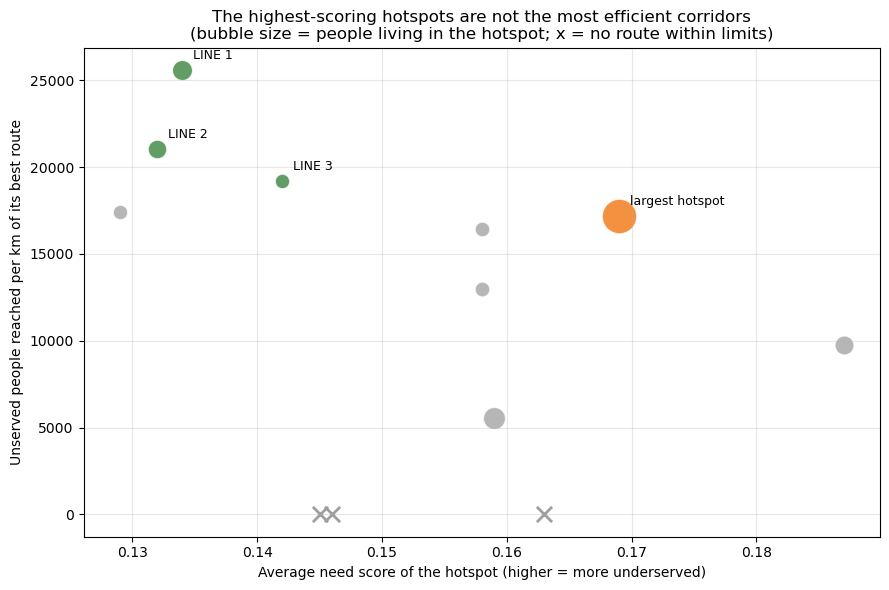

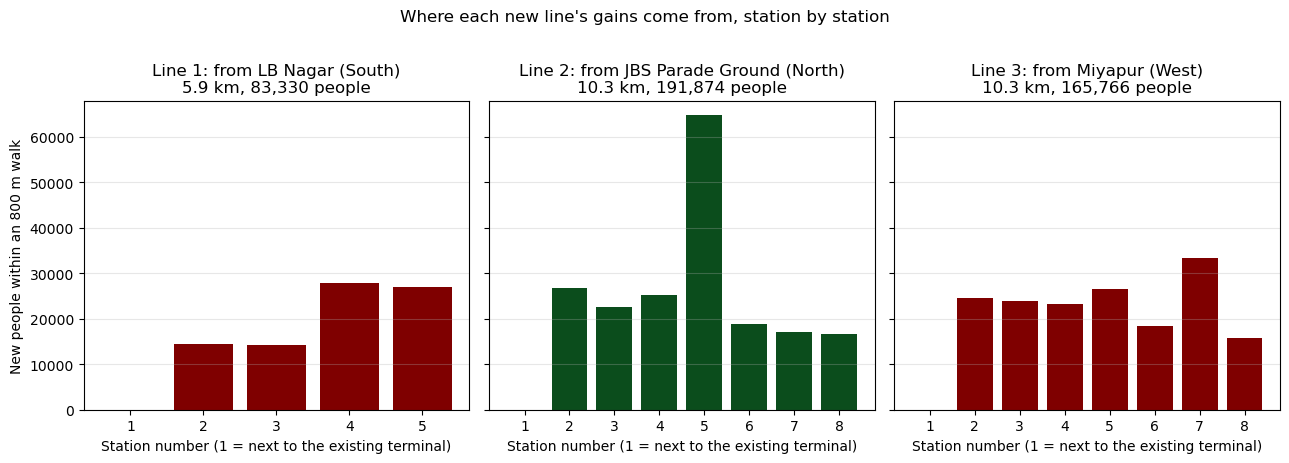

In [24]:
# Two data pictures for the website
import matplotlib.pyplot as plt

# ---------- Picture 1: need score vs how efficient the best route is, for all 12 hotspots ----------
t = table.copy()                                   # from the "Why these 3?" cell
t["won"] = t["result"].str.startswith("LINE")
t["no_route"] = t["people_per_km"].isna()
t["y"] = t["people_per_km"].fillna(0)
biggest = t["people"].idxmax()                     # the largest hotspot (your circled area)

fig, ax = plt.subplots(figsize=(9, 6))
for i, r in t.iterrows():
    colour = "#2e7d32" if r["won"] else ("#ef6c00" if i == biggest else "#9e9e9e")
    if r["no_route"]:
        ax.scatter(r["avg_need_score"], 0, s=120, color="#9e9e9e", marker="x", linewidths=2)
        continue
    ax.scatter(r["avg_need_score"], r["y"], s=r["people"] / 600, color=colour, alpha=0.75,
               edgecolor="white", linewidths=0.8)
    label = r["result"] if r["won"] else ("largest hotspot" if i == biggest else "")
    if label:
        ax.annotate(label, (r["avg_need_score"], r["y"]), textcoords="offset points",
                    xytext=(8, 8), fontsize=9)
ax.set_xlabel("Average need score of the hotspot (higher = more underserved)")
ax.set_ylabel("Unserved people reached per km of its best route")
ax.set_title("The highest-scoring hotspots are not the most efficient corridors\n"
             "(bubble size = people living in the hotspot; x = no route within limits)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("chart1_need_vs_efficiency.png", dpi=200, bbox_inches="tight")
plt.show()

# ---------- Picture 2: who each new station brings within walking distance ----------
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), sharey=True)
shade = {"Red": "#7f0000", "Blue": "#0a1f7a", "Green": "#0b4d1c"}
ext_of = {"Miyapur": "Red", "LB Nagar": "Red", "Nagole": "Blue", "Raidurg": "Blue",
          "JBS Parade Ground": "Green", "MG Bus Station": "Green"}
for ax, (_, ln) in zip(axes, lines.sort_values("rank").iterrows()):
    s = new_stations[new_stations["corridor"] == ln["rank"]].sort_values("stop")
    ax.bar(s["stop"], s["new_people_within_800m"], color=shade.get(ext_of.get(ln["starts_at"]), "#8e24aa"))
    ax.set_title(f"Line {ln['rank']}: from {ln['starts_at']} ({ln['area']})\n"
                 f"{ln['length_km']} km, {int(ln['catchment_people']):,} people")
    ax.set_xlabel("Station number (1 = next to the existing terminal)")
    ax.set_xticks(s["stop"])
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("New people within an 800 m walk")
fig.suptitle("Where each new line's gains come from, station by station", y=1.02)
plt.tight_layout()
plt.savefig("chart2_people_per_station.png", dpi=200, bbox_inches="tight")
plt.show()


## Notes for the write-up

**What the result is:** a ranked list of corridors where many people live far from any metro station, scored per km of line. Every corridor starts at a line end (an extension) or at an interchange station (a branch).

**What it is not:** a final alignment. Lines follow the shortest wide-road route, but real alignment needs ridership forecasts, land, curves, cost and engineering, so call these *priority corridors for further study*.

**Limitations to state**
- Operational stations come from OpenStreetMap, filtered by tags and by name. The start points (line ends and junctions) are listed by hand in `ANCHORS`.
- Road class (trunk, primary, secondary) is a stand-in for width. OSM lane counts are patchy, so they are used only where present.
- OpenStreetMap is missing some bus stops and schools, so scores are relative.
- Distance to job hubs stands in for commuting. It is not real travel data.
- Population is a WorldPop estimate, not a census count.
- Colleges come from OSM, with nearby points merged into one campus. Colleges are also inside the schools count, so they count a little extra on purpose.
- Station spacing (1.25 km) and walking distance (800 m) are rules of thumb. Catchments use square centres, so they are approximate.
- The grid starts at the southern edge of the study rectangle, so squares there may look farther from transit than they are.
- The 15 km route-length limit is the most sensitive setting. Raising it to 16 km changes two of the three lines (see the sensitivity cell).
- Ranking by unserved people per km favours short lines. Ranking by total people would give a different order.
- The proposed lines have not been compared with the official Phase 2 plan yet.
- Weights (metro 60%, job hubs 30%, bus 10%) are a judgement call. Bus is kept low on purpose, because this project is about metro lines. The robustness cell shows how much they matter.

**Interview story:** a simple average of the indicators favoured the city edge, because distances are largest there. Switching to demand x gap, counting each person only once, letting lines start only at ends or junctions, and routing them along wide roads made the result realistic.